In [6]:
# 1. 수집
# 2. 탐색
# 2-1) 데이터를 읽고, 구조(스키마)확인, 자료형

In [7]:
import koreanize_matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# pandas, seaborn 라이브러리 사용 옵션 설정
pd.set_option("display.max_columns", 100) #  최대 100개 열까지 표시한다.
pd.set_option("display.max_rows", 100) # 최대 100개 행까지 표시한다.
pd.set_option("display.width", 140) # 표의 출력 너비를 140자로 설정해 줄바꿈을 줄인다.
# seaborn 그래프의 기본 모양을 흰 배경과 격자선으로 설정하고, 노트북에 맞는 글자·요소 크기를 사용한다.
sns.set_theme(style="whitegrid", context="notebook")

In [9]:
df = pd.read_csv('train.csv')
# df.head(5)
df.head(5).T

,0,1,2,3,4
Id,1,2,3,4,5
MSSubClass,60,20,60,70,60
MSZoning,RL,RL,RL,RL,RL
LotFrontage,65.0,80.0,68.0,60.0,84.0
LotArea,8450,9600,11250,9550,14260
Street,Pave,Pave,Pave,Pave,Pave
Alley,NaN,NaN,NaN,NaN,NaN
LotShape,Reg,Reg,IR1,IR1,IR1
LandContour,Lvl,Lvl,Lvl,Lvl,Lvl
Utilities,AllPub,AllPub,AllPub,AllPub,AllPub


In [10]:
df.shape

(1460, 81)

In [11]:
# duplicated() 행->이전에 동일한 행이 존재하면 True 아니면 Fasle -> sum()집계하면 True 개수
df.duplicated().sum()

np.int64(0)

In [12]:
# 컬럼의 이름만 중복확인
df.columns.duplicated().sum()

np.int64(0)

In [13]:
# 자료형
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [14]:
# df[조건][열이름]
# df.loc[조건, [열이름]]
df[['PoolQC', 'PoolArea']]

display(df.loc[df['PoolQC'].isna(), ['PoolQC', 'PoolArea']]) # df[df['PoolQC'].isna()]['PoolQC', 'PoolArea']
display(df.loc[df['PoolQC'].notna(), ['PoolQC', 'PoolArea']])

,PoolQC,PoolArea
0,NaN,0
1,NaN,0
2,NaN,0
3,NaN,0
4,NaN,0
...,...,...
1455,NaN,0
1456,NaN,0
1457,NaN,0
1458,NaN,0


,PoolQC,PoolArea
197,Ex,512
810,Fa,648
1170,Gd,576
1182,Ex,555
1298,Gd,480
1386,Fa,519
1423,Gd,738


In [15]:
df.dtypes.value_counts()

str        43
int64      35
float64     3
Name: count, dtype: int64

In [16]:
# 변수 탐색 + 품질 검사(논리 검증)

In [37]:
# 고유값
# df[컬럼].nunique() 값
df['PoolQC'].nunique(dropna=False)

# t1 = [df[c].nunique(dropna=False) for c in df.columns]

# 같은 표현
t1 = []
for c in df.columns: # for문을 많이 사용해야....
  t1.append(df[c].nunique(dropna=False))

t1[:3]

[1460, 15, 5]

In [38]:
df.dtypes.values[:3]

array([dtype('int64'), dtype('int64'),
       <StringDtype(storage='python', na_value=nan)>], dtype=object)

In [39]:
# 고유값 품질 요약
unque_summary = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.values,
    'nunique(na)': [df[c].nunique(dropna=False) for c in df.columns], # t1
    'nunique(ratio)': [df[c].nunique(dropna=False)/len(df) for c in df.columns],
})

unque_summary[:3]

,column,dtype,nunique(na),nunique(ratio)
0,Id,int64,1460,1.000000
1,MSSubClass,int64,15,0.010274
2,MSZoning,str,5,0.003425


In [20]:
# 개별 변수의 고유값 상세히 탐색 value_counts()

df['Id'].value_counts(dropna=False)

Id
1       1
2       1
3       1
4       1
5       1
       ..
1456    1
1457    1
1458    1
1459    1
1460    1
Name: count, Length: 1460, dtype: int64

In [ ]:
for nc in df.select_dtypes('number').columns:
  display(df[nc].value_counts(dropna=False))


In [ ]:
for oc in df.select_dtypes('object').columns:
  display(df[oc].value_counts(dropna=False))

In [ ]:
for oc in df.select_dtypes('object').columns:
  print(len(df[oc].value_counts(dropna=False)))

In [40]:
# 결측치 품질 요약
# 탐색, 확인이 목적 -> 대체/다른값으로 기록, ....

na_summary = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.values,
    'na(count)': df.isna().sum(),
}).sort_values('na(count)', ascending=False)

na_summary[:3]

,column,dtype,na(count)
PoolQC,PoolQC,str,1453
MiscFeature,MiscFeature,str,1406
Alley,Alley,str,1369


In [25]:
# 변수값 논리검정

In [26]:
# 수치형 기술 통계량 점검
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [27]:
df.describe(include='object').T

C:\Users\user\AppData\Local\Temp\ipykernel_16580\1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


<Axes: >

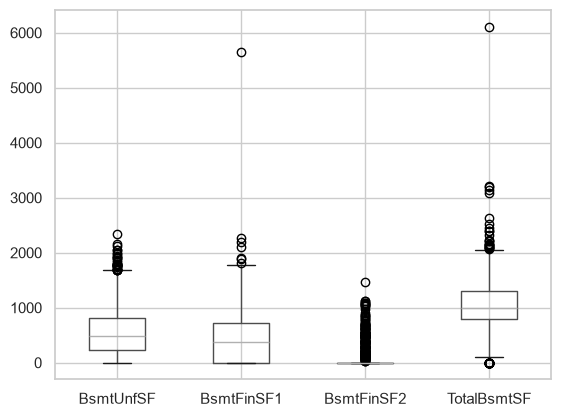

In [28]:
df.boxplot(['BsmtUnfSF','BsmtFinSF1','BsmtFinSF2', 'TotalBsmtSF'])

In [29]:
df[df['BsmtFinSF1'] == 5644]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1298,1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Gd,NaN,NaN,0,1,2008,New,Partial,160000


In [30]:
# 예시1) 가격·면적의 음수 여부: SalePrice, LotArea, GrLivArea가 0보다 작은 행을 찾는다.
# 예시2) 연도 관계: YearBuilt가 YrSold보다 큰 집을 찾는다. 리모델링 연도(YearRemodAdd)가 판매 연도보다 늦은지도 확인한다.
# 예시3) 면적 합계: GrLivArea가 1stFlrSF + 2ndFlrSF + LowQualFinSF와 맞는지 확인한다.
# 예시4) 방·욕실 수: BedroomAbvGr, FullBath, GarageCars 등에 음수나 비현실적인 값이 있는지 확인한다.
# 예시5) 월 범위: MoSold가 1~12 범위인지 확인한다.
# 예시6) 식별자 중복: Id가 중복되거나 비어 있는지 확인한다.

In [31]:
# 예시6) 식별자 중복: Id가 중복되거나 비어 있는지 확인한다.
# 전체1460개 고유값 1460 -> 식별자 검증

# RDB의 PK 검증
# 결측치 확인
print(df['Id'].isna().sum()) # 0 -> 식별자 결측치가 없다.
# 중복값 확인
print(df['Id'].duplicated().sum())

# 만약 위에서 하나라도 1이 있다면 조건식으로 행을 탐색
df[(df['Id'].isna() == True) | (df['Id'].duplicated() == True)]

0
0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [32]:
# 예시5) 월 범위: MoSold가 1~12 범위인지 확인한다.
df['MoSold'].unique() # 1 ~ 12 , 0,

array([ 2,  5,  9, 12, 10,  8, 11,  4,  1,  7,  3,  6])

In [33]:
df[(df['MoSold']<1) | (df['MoSold']>12)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [34]:
# 예시4) 방·욕실 수: BedroomAbvGr, FullBath, GarageCars 등에 음수나 비현실적인 값이 있는지 확인한다.

df[(df['BedroomAbvGr']<0) | (df['FullBath']<0) | (df['GarageCars']<0)]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [35]:
# 예시3) 면적 합계: GrLivArea가 1stFlrSF + 2ndFlrSF + LowQualFinSF와 맞는지 확인한다.
# df[['GrLivArea','1stFlrSF','2ndFlrSF','LowQualFinSF']].isna().sum()
# df[['GrLivArea','1stFlrSF','2ndFlrSF','LowQualFinSF']]

df[df['GrLivArea'] != (df['1stFlrSF']+df['2ndFlrSF']+df['LowQualFinSF'])]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [36]:
# 전치리 결측치,..... 이상치,........, 범주, 수치, 범주형, 서열,,....